# 포켓몬 GO 연구 · 3단계 감성 분포 비교 (코딩북 V1.2)

**분석 질문:** 별점(1~5점)에 따라 각 평가속성(A01~A08)에 대한 **긍정·중립·부정** 분포가 달라지는가?

- 입력: `PokemonGO_Merged_2500_V1_2(1).csv` (최종 수정 CSV로 교체 가능)
- 분석 단위: 리뷰 × 평가속성. 속성이 **언급된 값** `-1, 0, 1`만 해당 속성 분석에 포함하고 `9`(미언급)는 제외
- Pearson 카이제곱 검정, Cramér's V, 기대빈도 점검, 희소 셀의 조건부 몬테카를로 p값(고정 주변합), 8개 검정 BH-FDR 보정
- 희소 범주의 빈도가 0이면 해당 열을 제거한 실제 **5×k 분할표**에서 검정하며 자유도를 그에 맞게 계산
- p값은 별점과 감성 분포의 **관련성**을 검정하는 것이며 인과관계나 모집단의 감성 비중을 뜻하지 않음

> 주의: 병합 자료 중 2,000건은 이전 AI 예비 판정을 기반으로 작성되었으므로 코딩 정확도 검증과 통계적 유의성은 별개의 문제입니다.

## 1. 환경 설정 및 입력 데이터

In [2]:
!pip install --upgrade pip

Active code page: 65001
  Using cached pip-26.3-py3-none-any.whl.metadata (4.6 kB)
Using cached pip-26.3-py3-none-any.whl (2.0 MB)


ERROR: To modify pip, please run the following command:
C:\Users\jspark\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [6]:
%pip install statsmodels

Active code page: 65001
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -------------------------- ------------- 7.6/11.3 MB 52.1 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 37.2 MB/s  0:00:00
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)

   ---------------------------------------- 0/5 [wrapt]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ---------------- ----------------------- 2/5 [interface-meta]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   -----------------------

In [7]:
import statsmodels
print("statsmodels 버전:", statsmodels.__version__)

from statsmodels.stats.multitest import multipletests

print("정상적으로 불러왔습니다.")

statsmodels 버전: 0.15.0
정상적으로 불러왔습니다.


In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, random_table
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
from IPython.display import display

INPUT_FILE = Path('PokemonGO_Merged_2500_V1_2.csv')
OUTPUT_DIR = Path('PokemonGO_Stage3_Results')
OUTPUT_DIR.mkdir(exist_ok=True)
ASPECTS = {
    'A01':'게임 콘텐츠·플레이 경험', 'A02':'과금·게임 내 경제',
    'A03':'보상·확률·성취', 'A04':'기술적 안정성·이용 편의성',
    'A05':'공간적 접근성·지역 격차', 'A06':'사회적 상호작용·협력',
    'A07':'게임 운영·서비스 관리', 'A08':'기기·자원 부담·호환성',
}
SENTIMENTS = {-1:'부정', 0:'중립', 1:'긍정'}
RATINGS = [1,2,3,4,5]
MC_SAMPLES = 10000
RANDOM_SEED = 20261106

if not INPUT_FILE.exists():
    alternatives = sorted(Path('.').glob('PokemonGO_Merged_2500_V1_2*.csv'))
    raise FileNotFoundError(f'입력 파일 없음: {INPUT_FILE}; 후보: {alternatives}')
raw = pd.read_csv(INPUT_FILE, encoding='utf-8-sig', dtype={'ID':str}, low_memory=False)
print('데이터 크기:', raw.shape, '| 사용 파일:', INPUT_FILE)
display(raw[['ID','별점_숫자',*ASPECTS.keys()]].head(3))

데이터 크기: (2500, 19) | 사용 파일: PokemonGO_Merged_2500_V1_2.csv


,ID,별점_숫자,A01,A02,A03,A04,A05,A06,A07,A08
0,b27d1f9f-1a6e-4418-b197-d636b39e8bd8,1,9,9,9,-1,9,9,9,9
1,3d206e46-6971-4302-a0f7-1e53d15e22ad,1,9,9,9,-1,9,9,9,9
2,ea985b53-1d81-471c-bc8b-30849fb1e121,1,9,9,9,-1,9,9,9,-1


## 2. 데이터 품질 및 코드 검증

In [10]:
required = {'ID','별점_숫자',*ASPECTS.keys()}
missing = required - set(raw.columns)
assert not missing, f'필수 열 누락: {sorted(missing)}'
assert raw['ID'].notna().all() and not raw['ID'].duplicated().any(), 'ID 결측 또는 중복 존재'

df = raw.copy()
df['별점_숫자'] = pd.to_numeric(df['별점_숫자'], errors='coerce')
assert df['별점_숫자'].isin(RATINGS).all(), '별점 1~5 이외 또는 결측 존재'
for a in ASPECTS:
    df[a] = pd.to_numeric(df[a], errors='coerce')
    invalid = df[a].isna() | ~df[a].isin([-1,0,1,9])
    if invalid.any():
        examples = raw.loc[invalid, ['ID',a]].head(10).to_dict('records')
        raise ValueError(f'{a}에서 U/결측/유효하지 않은 코드 발견({invalid.sum()}건): {examples}')
    df[a] = df[a].astype(int)

counts = df['별점_숫자'].value_counts().reindex(RATINGS,fill_value=0)
print('별점별 표본 수:', counts.to_dict(), '총',len(df),'건')
if not (len(df)==2500 and (counts==500).all()):
    print('주의: 예상 표본구성(2500건, 별점별 500건)과 다릅니다. 실제 표본 구성으로 계산합니다.')
print('평가속성 8개 코드 검증 통과: -1/0/1/9만 존재')

별점별 표본 수: {1: 500, 2: 500, 3: 500, 4: 500, 5: 500} 총 2500 건
평가속성 8개 코드 검증 통과: -1/0/1/9만 존재


## 3. 별점 × 감성 교차표, 카이제곱, 효과크기

**분모 유의:** 속성별 언급 리뷰만 사용합니다. 미언급(9)은 감성의 한 범주가 아닙니다. 중립(0)은 해당 속성의 출현 사례입니다. 기대빈도가 5 미만인 셀은 보조로 고정 주변합 몬테카를로 검정의 p값을 사용합니다.

In [11]:
def compute_monte_carlo_p(table, observed_chi2, n_samples=10000, seed=42):
    """고정 주변합 무작위 분할표에 대한 Pearson χ² 꼬리확률 (+1 보정)."""
    rows = table.sum(axis=1).astype(int)
    cols = table.sum(axis=0).astype(int)
    rng = np.random.default_rng(seed)
    expected = np.outer(rows, cols) / table.sum()
    exceed = 0
    for _ in range(n_samples):
        draw = random_table.rvs(rows, cols, random_state=rng)
        sim_chi2 = np.sum((draw - expected)**2 / expected)
        if sim_chi2 >= observed_chi2 - 1e-12:
            exceed += 1
    return (exceed + 1) / (n_samples + 1)

results = []
long_rows = []
residual_rows = []
for idx, (a, name) in enumerate(ASPECTS.items()):
    sub = df.loc[df[a].isin([-1,0,1]), ['별점_숫자',a]].copy()
    all_counts = pd.crosstab(sub['별점_숫자'],sub[a]).reindex(
        index=RATINGS,columns=[-1,0,1],fill_value=0)
    # 0건인 감성 열은 검정용 분할표에서 제거한다.
    active = all_counts.loc[:, all_counts.sum(axis=0) > 0]
    active = active.loc[active.sum(axis=1)>0,:]
    n = len(sub)
    testable = active.shape[0]>=2 and active.shape[1]>=2
    chi2 = dof = p_asym = cramer = min_exp = np.nan
    low_exp = np.nan
    p_mc = np.nan
    p_selected = np.nan
    test_method = '검정 불가(출현 사례 또는 감성 범주 부족)'
    if testable:
        chi2,p_asym,dof,expected = chi2_contingency(active.to_numpy(),correction=False)
        cramer = np.sqrt(chi2 / (n * min(active.shape[0]-1, active.shape[1]-1)))
        min_exp=float(expected.min())
        low_exp=int((expected<5).sum())
        if low_exp>0:
            p_mc=compute_monte_carlo_p(active.to_numpy(),chi2,MC_SAMPLES,RANDOM_SEED+idx)
            p_selected=p_mc
            test_method=f'몬테카를로 조건부 p ({MC_SAMPLES:,}회)'
        else:
            p_selected=p_asym
            test_method='Pearson 카이제곱 근사 p'
        adj=(active.to_numpy()-expected)/np.sqrt(expected*(1-active.sum(axis=1).to_numpy()[:,None]/n)*(1-active.sum(axis=0).to_numpy()[None,:]/n))
        for i,rating in enumerate(active.index):
            for j,s in enumerate(active.columns):
                residual_rows.append({'코드':a,'평가속성':name,'별점':int(rating),'감성':SENTIMENTS[s], '조정표준화잔차':float(adj[i,j])})
    results.append({'코드':a,'평가속성':name,'출현사례수_n':n,'검정표_행수':active.shape[0],
                    '검정표_감성범주수':active.shape[1],'카이제곱':chi2,'자유도':dof,
                    '근사_p':p_asym,'최소_기대빈도':min_exp,'기대빈도5미만_셀수':low_exp,
                    '몬테카를로_p':p_mc,'최종선택_p':p_selected,'검정방식':test_method,
                    'Cramers_V':cramer})
    for rating in RATINGS:
        base=int(all_counts.loc[rating].sum())
        for val,label in SENTIMENTS.items():
            x=int(all_counts.loc[rating,val])
            long_rows.append({'코드':a,'평가속성':name,'별점':rating,'감성':label,
                              '빈도':x,'해당별점_속성출현수':base,
                              '출현리뷰중_감성비율_pct':round(x/base*100,2) if base else np.nan})

stats = pd.DataFrame(results)
valid = stats['최종선택_p'].notna()
stats['FDR_q'] = np.nan
stats.loc[valid,'FDR_q'] = multipletests(stats.loc[valid,'최종선택_p'],method='fdr_bh')[1]
stats['FDR_유의_0_05'] = stats['FDR_q'].lt(.05) & valid
breakdown=pd.DataFrame(long_rows)
residuals=pd.DataFrame(residual_rows)
display(stats[['코드','출현사례수_n','카이제곱','자유도','최종선택_p','FDR_q','Cramers_V','기대빈도5미만_셀수','검정방식']].round(4))

,코드,출현사례수_n,카이제곱,자유도,최종선택_p,FDR_q,Cramers_V,기대빈도5미만_셀수,검정방식
0,A01,862,181.6469,4,0.0000,0.0000,0.4591,0,Pearson 카이제곱 근사 p
1,A02,254,36.6836,8,0.0001,0.0002,0.2687,3,"몬테카를로 조건부 p (10,000회)"
2,A03,199,19.7924,8,0.0100,0.0133,0.2230,1,"몬테카를로 조건부 p (10,000회)"
3,A04,1011,79.4780,8,0.0001,0.0002,0.1983,5,"몬테카를로 조건부 p (10,000회)"
4,A05,87,15.1522,8,0.0538,0.0615,0.2951,10,"몬테카를로 조건부 p (10,000회)"
5,A06,321,52.2390,8,0.0000,0.0000,0.2853,0,Pearson 카이제곱 근사 p
6,A07,625,93.9414,8,0.0000,0.0000,0.2741,0,Pearson 카이제곱 근사 p
7,A08,57,11.7860,8,0.1507,0.1507,0.3215,11,"몬테카를로 조건부 p (10,000회)"


## 4. 논문용 결과표 및 상세 교차표

In [12]:
# 논문표에서 p<.001을 표기하는 경우 실제 저장값은 원래 수치로 보존합니다.
paper = stats[['코드','평가속성','출현사례수_n','카이제곱','자유도','최종선택_p','FDR_q','Cramers_V','검정방식']].copy()
paper.rename(columns={'출현사례수_n':'n','카이제곱':'χ²','자유도':'df',
                      '최종선택_p':'p','FDR_q':'q(BH-FDR)','Cramers_V':'Cramér V'},inplace=True)
display(paper.round(4))
# 별점별 감성 비율: 속성 출현 리뷰를 분모로 한 행 백분율
rate_table = breakdown.pivot(index=['코드','평가속성','별점'], columns='감성', values='출현리뷰중_감성비율_pct').reset_index()
count_table = breakdown.pivot(index=['코드','평가속성','별점'], columns='감성', values='빈도').reset_index()
print('별점별 감성 비율(%) 예시:')
display(rate_table.head(10))

stats.to_csv(OUTPUT_DIR/'01_감성_카이제곱_CramersV_FDR.csv', index=False, encoding='utf-8-sig')
paper.to_csv(OUTPUT_DIR/'02_논문용_감성차이_검정표.csv', index=False, encoding='utf-8-sig')
breakdown.to_csv(OUTPUT_DIR/'03_별점별_감성_상세.csv', index=False, encoding='utf-8-sig')
rate_table.to_csv(OUTPUT_DIR/'04_별점별_감성비율_논문표.csv', index=False, encoding='utf-8-sig')
count_table.to_csv(OUTPUT_DIR/'05_별점별_감성빈도_논문표.csv', index=False, encoding='utf-8-sig')
residuals.to_csv(OUTPUT_DIR/'06_조정표준화잔차.csv', index=False, encoding='utf-8-sig')
print('결과 CSV 6개 저장:',OUTPUT_DIR.resolve())

,코드,평가속성,n,χ²,df,p,q(BH-FDR),Cramér V,검정방식
0,A01,게임 콘텐츠·플레이 경험,862,181.6469,4,0.0000,0.0000,0.4591,Pearson 카이제곱 근사 p
1,A02,과금·게임 내 경제,254,36.6836,8,0.0001,0.0002,0.2687,"몬테카를로 조건부 p (10,000회)"
2,A03,보상·확률·성취,199,19.7924,8,0.0100,0.0133,0.2230,"몬테카를로 조건부 p (10,000회)"
3,A04,기술적 안정성·이용 편의성,1011,79.4780,8,0.0001,0.0002,0.1983,"몬테카를로 조건부 p (10,000회)"
4,A05,공간적 접근성·지역 격차,87,15.1522,8,0.0538,0.0615,0.2951,"몬테카를로 조건부 p (10,000회)"
5,A06,사회적 상호작용·협력,321,52.2390,8,0.0000,0.0000,0.2853,Pearson 카이제곱 근사 p
6,A07,게임 운영·서비스 관리,625,93.9414,8,0.0000,0.0000,0.2741,Pearson 카이제곱 근사 p
7,A08,기기·자원 부담·호환성,57,11.7860,8,0.1507,0.1507,0.3215,"몬테카를로 조건부 p (10,000회)"


별점별 감성 비율(%) 예시:


감성,코드,평가속성,별점,긍정,부정,중립
0,A01,게임 콘텐츠·플레이 경험,1,13.04,86.96,0.00
1,A01,게임 콘텐츠·플레이 경험,2,18.27,81.73,0.00
2,A01,게임 콘텐츠·플레이 경험,3,39.49,60.51,0.00
3,A01,게임 콘텐츠·플레이 경험,4,50.77,49.23,0.00
4,A01,게임 콘텐츠·플레이 경험,5,73.47,26.53,0.00
5,A02,과금·게임 내 경제,1,8.96,79.10,11.94
6,A02,과금·게임 내 경제,2,7.14,75.00,17.86
7,A02,과금·게임 내 경제,3,23.40,70.21,6.38
8,A02,과금·게임 내 경제,4,37.78,51.11,11.11
9,A02,과금·게임 내 경제,5,47.76,43.28,8.96


결과 CSV 6개 저장: D:\vscode_project\포켓몬고\PokemonGO_Stage3_Results


## 5. 감성 분포 시각화

C:\Users\jspark\AppData\Local\Temp\ipykernel_10244\33550441.py:11: UserWarning: Glyph 48512 (\N{HANGUL SYLLABLE BU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\jspark\AppData\Local\Temp\ipykernel_10244\33550441.py:11: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\jspark\AppData\Local\Temp\ipykernel_10244\33550441.py:11: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\jspark\AppData\Local\Temp\ipykernel_10244\33550441.py:11: UserWarning: Glyph 47549 (\N{HANGUL SYLLABLE RIB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\jspark\AppData\Local\Temp\ipykernel_10244\33550441.py:11: UserWarning: Glyph 44557 (\N{HANGUL SYLLABLE GEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\jspark\AppData\Local\Temp\ipykernel_10244\33550441.py:12: UserWarning: Glyph 48512 (\N{HANGUL SYLLABLE BU}) missing from f

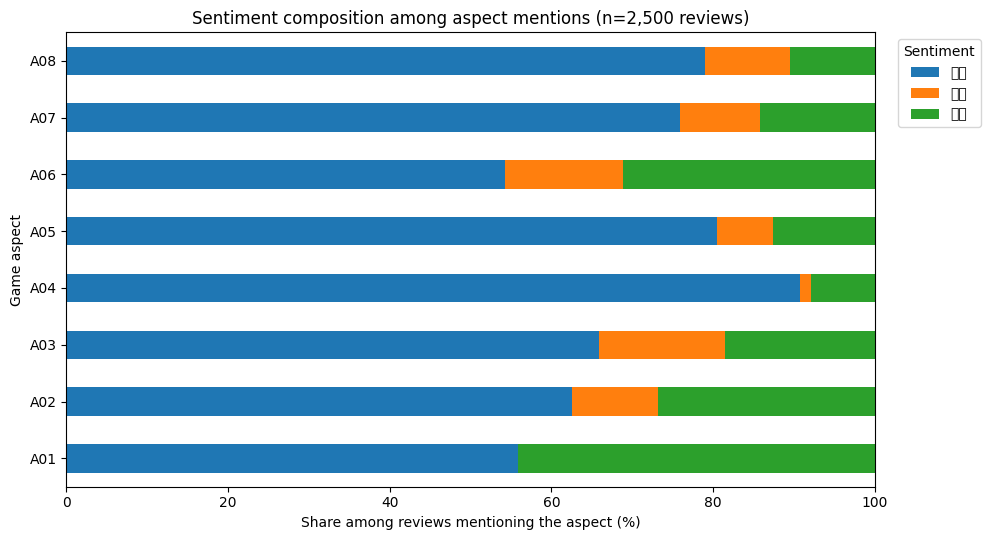

In [13]:
# 평가속성별 전체 감성 구성비. 서로 다른 속성의 언급 수가 달라, 분모는 속성별 출현 리뷰 수.
summary = breakdown.groupby(['코드','감성'])['빈도'].sum().unstack(fill_value=0)
summary=summary.reindex(index=list(ASPECTS),columns=['부정','중립','긍정'],fill_value=0)
shares=summary.div(summary.sum(axis=1),axis=0)*100
ax=shares.plot(kind='barh',stacked=True,figsize=(10,5.5))
ax.set_xlabel('Share among reviews mentioning the aspect (%)')
ax.set_ylabel('Game aspect')
ax.set_xlim(0,100)
ax.set_title('Sentiment composition among aspect mentions (n=2,500 reviews)')
ax.legend(title='Sentiment',bbox_to_anchor=(1.02,1),loc='upper left')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'Figure_01_Aspect_Sentiment_Shares.png',dpi=180,bbox_inches='tight')
plt.show()

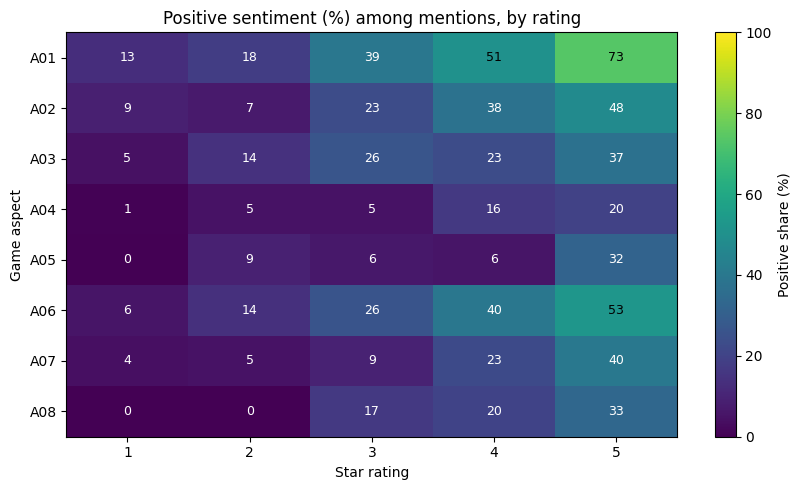

※ 매우 적은 출현 건수에서는 비율 변동이 큽니다. 반드시 상세 빈도표와 함께 해석하십시오.


In [14]:
# 별점별 긍정 비율 (각 별점에서 해당 속성을 언급한 리뷰를 분모로 계산)
positive = breakdown.query("감성 == '긍정'").pivot(index='코드',columns='별점',values='출현리뷰중_감성비율_pct').reindex(index=list(ASPECTS),columns=RATINGS)
fig,ax=plt.subplots(figsize=(8.5,5))
im=ax.imshow(positive.to_numpy(dtype=float),aspect='auto',vmin=0,vmax=100,cmap='viridis')
ax.set_xticks(range(5),RATINGS)
ax.set_yticks(range(8),list(ASPECTS))
ax.set_xlabel('Star rating')
ax.set_ylabel('Game aspect')
ax.set_title('Positive sentiment (%) among mentions, by rating')
for i in range(8):
    for j in range(5):
        v=positive.iloc[i,j]
        ax.text(j,i, '—' if pd.isna(v) else f'{v:.0f}',ha='center',va='center',color='white' if pd.notna(v) and v<50 else 'black',fontsize=9)
fig.colorbar(im,ax=ax,label='Positive share (%)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'Figure_02_Positive_Share_Heatmap.png',dpi=180,bbox_inches='tight')
plt.show()
print('※ 매우 적은 출현 건수에서는 비율 변동이 큽니다. 반드시 상세 빈도표와 함께 해석하십시오.')

## 6. 해석 및 연구방법 유의사항

- 각 검정의 귀무가설은 **별점과 해당 평가속성의 감성 범주가 독립**이라는 것입니다.
- 검정은 **속성이 언급된 리뷰만** 대상으로 합니다. 별점별 속성 출현 차이(2단계)와 구분하십시오.
- 감성 0건인 열은 χ² 계산에서 제외합니다. 해당 속성의 감성 범주가 1개뿐이면 검정하지 않습니다.
- 기대빈도 5 미만 셀이 있으면 본 노트북은 고정 주변합 **몬테카를로 p값**을 우선 사용하며, 그 p값에 BH-FDR을 적용합니다. 몬테카를로 표본 수가 10,000회인 경우 가장 작은 보고 가능한 p값은 약 .0001입니다.
- 8개 평가속성은 한 리뷰에서 중복 출현할 수 있습니다. 각 속성에 대한 검정은 개별적으로 수행되며, 서로 독립적인 리뷰 집단이라고 해석해서는 안 됩니다.
- 별점별 균등 추출 자료이므로 수치는 별점에 조건부인 표본 비교입니다. 전체 사용자 리뷰의 별점 분포나 전체 감성 비중을 대표하지 않습니다.
- AI 기반 예비 라벨을 포함한 병합 자료의 해석은 인간 검증 수준을 명시해야 합니다.

**생성 파일:** `PokemonGO_Stage3_Results/`의 검정표·별점별 감성표·잔차표 및 그래프 2개.